<center><h1>Enriquez_Scott_HW7</h1></center>

Name: Scott Enriquez
<br>
GitHub Username: `scottenriquez`
<br>

In [1]:
%pip install -q imbalanced-learn==0.14.2 matplotlib==3.11.2 numpy==2.5.4 'pandas[output-formatting]==3.1.0' scikit-learn==1.9.1 seaborn==0.13.2 scipy==1.18.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imbalanced_pipeline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, jaccard_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

In [3]:
Path('results').mkdir(exist_ok=True)

### (a) Download the Anuran Calls (MFCCs) Data Set

In [4]:
frog_sound_data = pd.read_csv('data/Frogs_MFCCs.csv')
targets = ['Family', 'Genus', 'Species']
non_data_columns = ['RecordID']
features = frog_sound_data.columns.drop(targets + non_data_columns)
training_x_data, test_x_data, training_y_data, test_y_data = (
    train_test_split(frog_sound_data[features], frog_sound_data[targets],
                     test_size=0.3, random_state=9999,
                     shuffle=True, stratify=frog_sound_data[targets]))

### (b) Train a classifier for each label

#### (i) Research

Exact match score refers to marking a prediction as correct only if all classifications are correct. For example, two of three still results in an error for the entire prediction. Hamming loss is an approach that is more forgiving. Instead, it evaluates each label independently and produces a number between zero and one that accounts for correct and incorrect classifications within the same prediction. Using the same example, the two of three correct would produce a Hamming loss of 1/3 or 0.333. Hamming score measures the fraction of correctly predicted labels to total predicted labels.

In [5]:
def compute_hamming_score(actual_labels, predicted_labels):
    row_scores = []
    for actual_row, predicted_row in zip(actual_labels.to_numpy(), predicted_labels.to_numpy()):
        actual_label_set = set(actual_row)
        predicted_label_set = set(predicted_row)
        row_scores.append(
            len(actual_label_set & predicted_label_set) / len(actual_label_set | predicted_label_set))
    return np.mean(row_scores)

#### (ii) Train a SVM for each of the labels

In [6]:
def evaluate_classifiers(report_name, classifiers_by_label, training_x_data, training_y_data,
                         test_x_data, test_y_data):
    evaluation_results = []
    for dataset_name, x_data, y_data in [
        ('Training', training_x_data, training_y_data),
        ('Test', test_x_data, test_y_data),
    ]:
        assignments = pd.DataFrame(index=y_data.index)
        for label in targets:
            classifier = classifiers_by_label[label]
            assignments[label] = classifier.predict(x_data[features])
        incorrect_labels = assignments != y_data[targets]
        evaluation_result = {'model': report_name, 'dataset': dataset_name}
        for label in targets:
            evaluation_result[f'{label.lower()}_misclassification'] = incorrect_labels[label].mean()
        evaluation_result['exact_match'] = (~incorrect_labels).all(axis=1).mean()
        evaluation_result['hamming_loss'] = incorrect_labels.to_numpy().mean()
        evaluation_result['hamming_score'] = compute_hamming_score(y_data[targets], assignments)
        evaluation_results.append(evaluation_result)
    return pd.DataFrame(evaluation_results)

In [7]:
grid_search_results_1bii = {}
cross_validation_results_by_label_1bii = []
for label in targets:
    support_vector_classifier_pipeline = (
        make_pipeline(StandardScaler(), OneVsRestClassifier(SVC(kernel='rbf', random_state=9999))))
    param_grid = {
        'onevsrestclassifier__estimator__C': np.logspace(-4, 4, 10),
        'onevsrestclassifier__estimator__gamma': np.logspace(-4, 4, 10)
    }
    grid_search_cross_validation = GridSearchCV(
        support_vector_classifier_pipeline,
        param_grid=param_grid,
        scoring='accuracy',
        cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=9999),
        n_jobs=-1
    )
    grid_search_cross_validation.fit(training_x_data[features], training_y_data[label])
    grid_search_results_1bii[label] = grid_search_cross_validation
    cross_validation_results = pd.DataFrame(grid_search_cross_validation.cv_results_)[
        ['param_onevsrestclassifier__estimator__C', 'param_onevsrestclassifier__estimator__gamma', 'mean_test_score']]
    cross_validation_results['cross_validation_error'] = 1 - cross_validation_results['mean_test_score']
    cross_validation_results['label'] = label
    cross_validation_results_by_label_1bii.append(cross_validation_results)

In [8]:
cross_validation_results_1bii = pd.concat(cross_validation_results_by_label_1bii, ignore_index=True).rename(columns={
    'param_onevsrestclassifier__estimator__C': 'C',
    'param_onevsrestclassifier__estimator__gamma': 'gamma'
})
cross_validation_results_1bii.to_csv('results/1bii_gaussian_svc_cross_validation_results.csv', index=False)
best_parameters_by_label_1bii = []
for label in targets:
    grid_search_result = grid_search_results_1bii[label]
    best_parameters_by_label_1bii.append({
        'label': label,
        'C': grid_search_result.best_params_['onevsrestclassifier__estimator__C'],
        'gamma': grid_search_result.best_params_['onevsrestclassifier__estimator__gamma'],
        'cross_validation_accuracy': grid_search_result.best_score_,
        'cross_validation_error': 1 - grid_search_result.best_score_
    })
best_parameters_by_label_1bii = pd.DataFrame(best_parameters_by_label_1bii)
best_parameters_by_label_1bii.to_csv('results/1bii_gaussian_svc_best_parameters.csv', index=False)
display(best_parameters_by_label_1bii)

,label,C,gamma,cross_validation_accuracy,cross_validation_error
0,Family,2.782559,0.046416,0.992852,0.007148
1,Genus,2.782559,0.046416,0.990468,0.009532
2,Species,2.782559,0.046416,0.990071,0.009929


In [9]:
best_classifiers_1bii = {}
for label in targets:
    support_vector_classifier_pipeline = (
        make_pipeline(StandardScaler(), OneVsRestClassifier(SVC(kernel='rbf', random_state=9999))))
    support_vector_classifier_pipeline.set_params(**grid_search_results_1bii[label].best_params_)
    support_vector_classifier_pipeline.fit(training_x_data[features], training_y_data[label])
    best_classifiers_1bii[label] = support_vector_classifier_pipeline
classifier_evaluation_1bii = evaluate_classifiers('Gaussian Support Vector Classifier', best_classifiers_1bii,
                                                  training_x_data, training_y_data,
                                                  test_x_data, test_y_data)

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [10]:
grid_search_results_1biii = {}
cross_validation_results_by_label_1biii = []
for label in targets:
    support_vector_classifier_pipeline = (
        make_pipeline(StandardScaler(), OneVsRestClassifier(
            LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=100000, random_state=9999))))
    param_grid = {
        'onevsrestclassifier__estimator__C': np.logspace(-4, 4, 10)
    }
    grid_search_cross_validation = GridSearchCV(
        support_vector_classifier_pipeline,
        param_grid=param_grid,
        scoring='accuracy',
        cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=9999),
        n_jobs=-1
    )
    grid_search_cross_validation.fit(training_x_data[features], training_y_data[label])
    grid_search_results_1biii[label] = grid_search_cross_validation
    cross_validation_results = pd.DataFrame(grid_search_cross_validation.cv_results_)[
        ['param_onevsrestclassifier__estimator__C', 'mean_test_score']]
    cross_validation_results['cross_validation_error'] = 1 - cross_validation_results['mean_test_score']
    cross_validation_results['label'] = label
    cross_validation_results_by_label_1biii.append(cross_validation_results)

In [11]:
cross_validation_results_1biii = pd.concat(cross_validation_results_by_label_1biii, ignore_index=True).rename(columns={
    'param_onevsrestclassifier__estimator__C': 'C'
})
cross_validation_results_1biii.to_csv('results/1biii_l1_svc_cross_validation_results.csv', index=False)
best_parameters_by_label_1biii = pd.DataFrame([
    {
        'label': label,
        'C': grid_search_results_1biii[label].best_params_['onevsrestclassifier__estimator__C'],
        'cross_validation_accuracy': grid_search_results_1biii[label].best_score_,
        'cross_validation_error': 1 - grid_search_results_1biii[label].best_score_
    }
    for label in targets
])
best_parameters_by_label_1biii.to_csv('results/1biii_l1_svc_best_parameters.csv', index=False)
display(best_parameters_by_label_1biii)

,label,C,cross_validation_accuracy,cross_validation_error
0,Family,2.782559,0.938048,0.061952
1,Genus,2.782559,0.954329,0.045671
2,Species,21.544347,0.961084,0.038916


In [12]:
best_classifiers_1biii = {}
for label in targets:
    support_vector_classifier_pipeline = (
        make_pipeline(StandardScaler(), OneVsRestClassifier(
            LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=100000, random_state=9999))))
    support_vector_classifier_pipeline.set_params(**grid_search_results_1biii[label].best_params_)
    support_vector_classifier_pipeline.fit(training_x_data[features], training_y_data[label])
    best_classifiers_1biii[label] = support_vector_classifier_pipeline
classifier_evaluation_1biii = evaluate_classifiers('L1-Penalized Support Vector Classifier', best_classifiers_1biii,
                                                   training_x_data, training_y_data,
                                                   test_x_data, test_y_data)

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [13]:
grid_search_results_1biv = {}
cross_validation_results_by_label_1biv = []
for label in targets:
    support_vector_classifier_pipeline = (
        make_imbalanced_pipeline(StandardScaler(),
                                 SMOTE(random_state=9999),
                                 OneVsRestClassifier(
                                     LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=100000,
                                               random_state=9999))))
    param_grid = {
        'onevsrestclassifier__estimator__C': np.logspace(-4, 4, 10)
    }
    grid_search_cross_validation = GridSearchCV(
        support_vector_classifier_pipeline,
        param_grid=param_grid,
        scoring='accuracy',
        cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=9999),
        n_jobs=-1
    )
    grid_search_cross_validation.fit(training_x_data[features], training_y_data[label])
    grid_search_results_1biv[label] = grid_search_cross_validation
    cross_validation_results = pd.DataFrame(grid_search_cross_validation.cv_results_)[
        ['param_onevsrestclassifier__estimator__C', 'mean_test_score']]
    cross_validation_results['cross_validation_error'] = 1 - cross_validation_results['mean_test_score']
    cross_validation_results['label'] = label
    cross_validation_results_by_label_1biv.append(cross_validation_results)

In [14]:
cross_validation_results_1biv = pd.concat(cross_validation_results_by_label_1biv, ignore_index=True).rename(columns={
    'param_onevsrestclassifier__estimator__C': 'C'
})
cross_validation_results_1biv.to_csv('results/1biv_l1_smote_svc_cross_validation_results.csv', index=False)
best_parameters_by_label_1biv = pd.DataFrame([
    {
        'label': label,
        'C': grid_search_results_1biv[label].best_params_['onevsrestclassifier__estimator__C'],
        'cross_validation_accuracy': grid_search_results_1biv[label].best_score_,
        'cross_validation_error': 1 - grid_search_results_1biv[label].best_score_
    }
    for label in targets
])
best_parameters_by_label_1biv.to_csv('results/1biv_l1_smote_svc_best_parameters.csv', index=False)
display(best_parameters_by_label_1biv)

,label,C,cross_validation_accuracy,cross_validation_error
0,Family,21.544347,0.925738,0.074262
1,Genus,2.782559,0.924343,0.075657
2,Species,2.782559,0.961084,0.038916


In [15]:
best_classifiers_1biv = {}
for label in targets:
    support_vector_classifier_pipeline = (
        make_imbalanced_pipeline(StandardScaler(),
                                 SMOTE(random_state=9999),
                                 OneVsRestClassifier(
                                     LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=100000,
                                               random_state=9999))))
    support_vector_classifier_pipeline.set_params(**grid_search_results_1biv[label].best_params_)
    support_vector_classifier_pipeline.fit(training_x_data[features], training_y_data[label])
    best_classifiers_1biv[label] = support_vector_classifier_pipeline
classifier_evaluation_1biv = evaluate_classifiers('SMOTE L1-Penalized Support Vector Classifier', best_classifiers_1biv,
                                                  training_x_data,
                                                  training_y_data,
                                                  test_x_data, test_y_data)

##### Comparison

In [16]:
display(pd.concat([classifier_evaluation_1bii, classifier_evaluation_1biii, classifier_evaluation_1biv],
                  ignore_index=True).sort_values(
    by=['dataset'], ascending=False))

,model,dataset,family_misclassification,genus_misclassification,species_misclassification,exact_match,hamming_loss,hamming_score
0,Gaussian Support Vector Classifier,Training,0.001191,0.000993,0.001191,0.998213,0.001125,0.998670
2,L1-Penalized Support Vector Classifier,Training,0.059770,0.041303,0.034353,0.922955,0.045142,0.945929
4,SMOTE L1-Penalized Support Vector Classifier,Training,0.072478,0.068308,0.033161,0.880858,0.057983,0.925457
1,Gaussian Support Vector Classifier,Test,0.008800,0.014358,0.015748,0.983326,0.012969,0.985780
3,L1-Penalized Support Vector Classifier,Test,0.070403,0.054192,0.050486,0.909217,0.058360,0.932561
5,SMOTE L1-Penalized Support Vector Classifier,Test,0.083835,0.085225,0.055581,0.859194,0.074880,0.906623


By Hamming loss, Hamming score, and exact match score using the test data, the best option is the Gaussian support vector classifier approach by a clear margin.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

### (b) Determine which family is the majority

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [17]:
monte_carlo_simulations = []
for simulation in range(50):
    simulation_calinski_harabasz_scores_by_k = {}
    simulation_cluster_assignments_by_k = {}
    # (a)
    # k=1 throws an error, so I skip it
    # ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)
    for k in range(2, 51):
        k_means_model = KMeans(n_clusters=k, random_state=simulation)
        cluster_assignments = k_means_model.fit_predict(frog_sound_data[features])
        simulation_calinski_harabasz_scores_by_k[k] = calinski_harabasz_score(frog_sound_data[features],
                                                                              cluster_assignments)
        simulation_cluster_assignments_by_k[k] = cluster_assignments
    simulation_best_k = max(simulation_calinski_harabasz_scores_by_k, key=simulation_calinski_harabasz_scores_by_k.get)
    simulation_cluster_assignments_for_best_k = pd.Series(simulation_cluster_assignments_by_k[simulation_best_k],
                                                          index=frog_sound_data.index)
    # (b)
    simulation_predictions_for_best_k = pd.DataFrame(index=frog_sound_data.index)
    for label in targets:
        simulation_majority_label_by_cluster_for_best_k = (
            frog_sound_data[label].groupby(simulation_cluster_assignments_for_best_k).agg(
                lambda labels: labels.mode()[0]))
        simulation_predictions_for_best_k[label] = simulation_cluster_assignments_for_best_k.map(
            simulation_majority_label_by_cluster_for_best_k)
    # (c)
    simulation_incorrect_labels_for_best_k = simulation_predictions_for_best_k != frog_sound_data[targets]
    simulation_hamming_loss_for_best_k = simulation_incorrect_labels_for_best_k.to_numpy().mean()
    monte_carlo_simulations.append({
        'simulation': simulation,
        'k': simulation_best_k,
        'calinski_harabasz_score': simulation_calinski_harabasz_scores_by_k[simulation_best_k],
        'hamming_distance': simulation_incorrect_labels_for_best_k.sum(axis=1).mean(),
        'hamming_loss': simulation_hamming_loss_for_best_k,
        'hamming_score': compute_hamming_score(frog_sound_data[targets], simulation_predictions_for_best_k)
    })
monte_carlo_simulations = pd.DataFrame(monte_carlo_simulations)
monte_carlo_simulations.to_csv('results/2_k_means_monte_carlo_results.csv', index=False)
monte_carlo_summary = monte_carlo_simulations[['k', 'hamming_distance', 'hamming_loss', 'hamming_score']].agg(
    ['mean', 'std'])
monte_carlo_summary.to_csv('results/2_k_means_monte_carlo_summary.csv')
display(monte_carlo_summary)
display(monte_carlo_simulations['k'].value_counts().sort_index())

,k,hamming_distance,hamming_loss,hamming_score
mean,2.0,8.956220e-01,2.985407e-01,6.818902e-01
std,0.0,1.121495e-16,5.607473e-17,1.121495e-16


k
2    50
Name: count, dtype: int64

All simulations picked `k=2`.

## 3. ISLR 12.6.2

In [18]:
dissimilarity_matrix = np.array([
    [0.0, 0.3, 0.4, 0.7],
    [0.3, 0.0, 0.5, 0.8],
    [0.4, 0.5, 0.0, 0.45],
    [0.7, 0.8, 0.45, 0.0]
])
condensed_dissimilarities = squareform(dissimilarity_matrix)

##### (a)

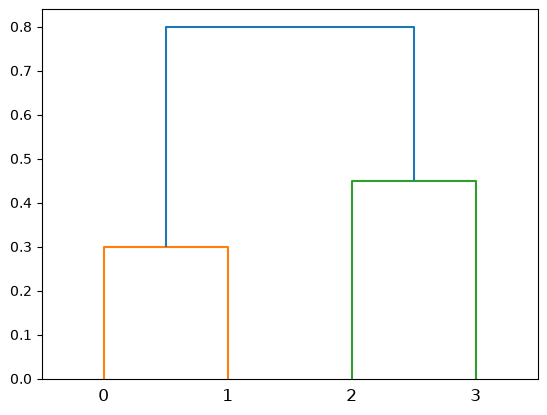

In [19]:
complete_linkage = linkage(condensed_dissimilarities, method='complete')
dendrogram(complete_linkage)
plt.show()

##### (b)

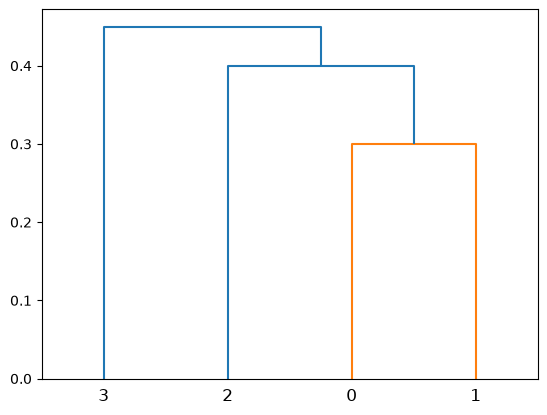

In [20]:
single_linkage = linkage(condensed_dissimilarities, method='single')
dendrogram(single_linkage)
plt.show()

##### (c)
Using zero-based indexing, 0 and 1 would belong to the first cluster. 2 and 3 would belong to the second cluster.

##### (d)
Using zero-based indexing, 3 would belong to the first cluster. 0, 1, and 2 would belong to the second cluster.

##### (e)

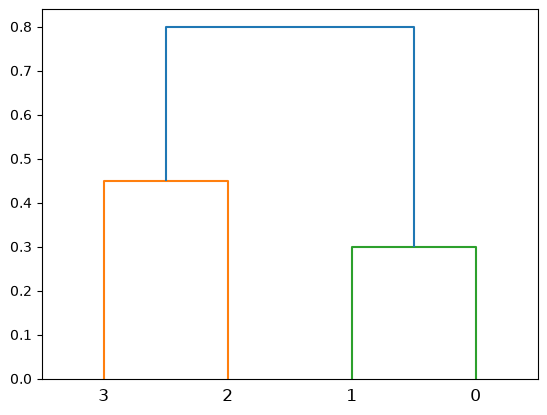

In [21]:
dendrogram(complete_linkage, distance_sort='descending')
plt.show()